In [1]:
import scanpy as sc
import numpy as np
adata_HD = sc.read("./h5ad/adata_HD.h5ad")
tp = adata_HD[adata_HD.obs["batch"]=="nS06"]
sc.pp.normalize_total(tp, target_sum=1e4)  
sc.pp.log1p(tp)   
tp.obs["in_plasma"] = [('Plasma cell'==t) for t in tp.obs["type"]]
tp.obs["in_plasma"] = tp.obs["in_plasma"].astype("str")

# DEG
sc.tl.rank_genes_groups(
    tp,
    groupby="in_plasma",
    groups=["True"],
    reference="False",
    method="wilcoxon"
)

# result
deg_df = sc.get.rank_genes_groups_df(tp, group="True")
deg_df["log2fc"] = deg_df["logfoldchanges"] / np.log(2)
sig = deg_df[(deg_df["pvals_adj"] < 0.05) & (np.abs(deg_df["log2fc"]) > 1.0)]

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Background points: 68, Highlighted target points: 5


/tmp/ipykernel_1477400/3128704318.py:110: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([str(int(n)) for n in  ax.get_xticks()], fontsize=16)
/tmp/ipykernel_1477400/3128704318.py:167: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


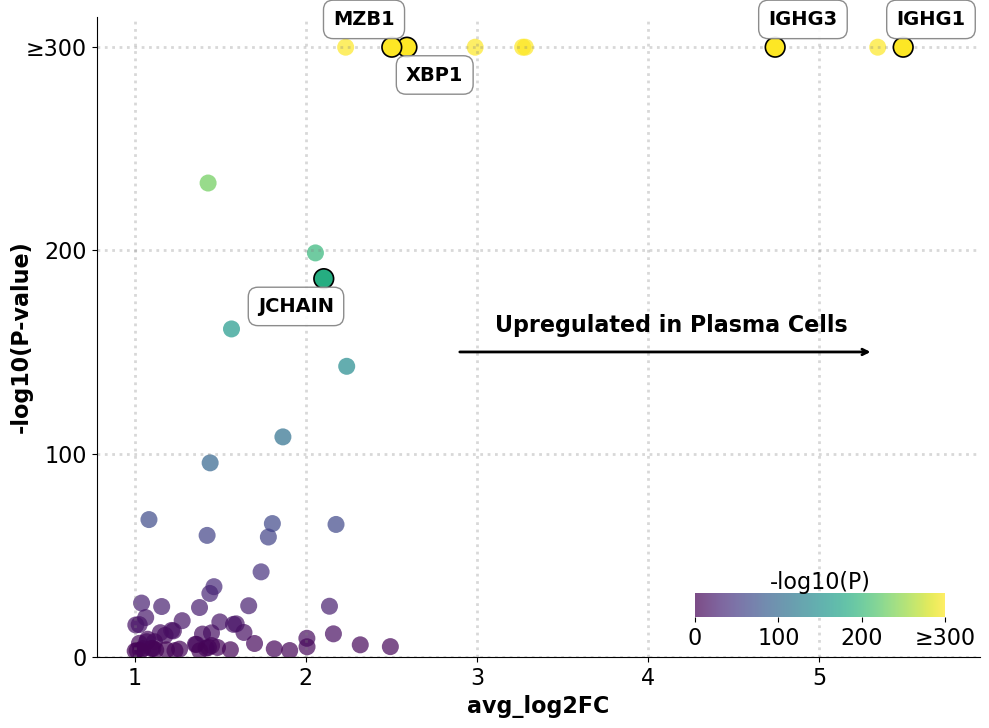

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# ================= Configuration =================
TARGET_KEYWORDS = ['IGHG', 'MZB1', 'XBP1', 'JCHAIN']

MANUAL_OFFSETS = {
    'IGHG':  (20, 20),   
    'MZB1':  (-20, 20),  
    'XBP1':  (20, -20),  
    'JCHAIN': (-20, -20) 
}

FIG_SIZE = (10, 8) 
BG_POINT_SIZE = 150       
TARGET_POINT_SIZE = 200  
TARGET_LINE_WIDTH = 1.2  
FONT_SIZE_LABEL = 14
MIN_PVAL_REPLACE = 1e-300
CMAP_NAME = 'viridis' 
# ===============================================

# 1. Data preparation
plot_df = sig.copy()
plot_df = plot_df[plot_df['log2fc'] > 0].reset_index(drop=True)

plot_df['pvals_plot'] = plot_df['pvals'].replace(0, MIN_PVAL_REPLACE)
plot_df['neg_log10_p'] = plot_df['pvals_plot'].apply(lambda x: -np.log10(x))

mask_target = plot_df['names'].astype(str).apply(lambda x: any(k in str(x) for k in TARGET_KEYWORDS))
df_targets = plot_df[mask_target]
df_background = plot_df[~mask_target]

print(f"Background points: {len(df_background)}, Highlighted target points: {len(df_targets)}")

# ================= Create a single canvas =================
# Create only one axis for plotting
fig, ax = plt.subplots(figsize=FIG_SIZE)

# ================= Global normalization =================
all_neg_log_p = pd.concat([df_background['neg_log10_p'], df_targets['neg_log10_p']]) if len(df_targets) > 0 else df_background['neg_log10_p']
vmin = 0 
vmax = all_neg_log_p.max() 
norm = Normalize(vmin=vmin, vmax=vmax)

# ================= Draw scatter plot =================
sc = ax.scatter(df_background['log2fc'], 
                df_background['neg_log10_p'], 
                c=df_background['neg_log10_p'], 
                cmap=CMAP_NAME,       
                norm=norm,             
                s=BG_POINT_SIZE, 
                alpha=0.7,             
                edgecolors='none', 
                zorder=1)

if len(df_targets) > 0:
    ax.scatter(df_targets['log2fc'], 
               df_targets['neg_log10_p'], 
               c=df_targets['neg_log10_p'], 
               cmap=CMAP_NAME,       
               norm=norm,             
               s=TARGET_POINT_SIZE, 
               alpha=1.0,
               edgecolors='black',    
               linewidths=TARGET_LINE_WIDTH,  
               zorder=10)

    # 4. Manual annotation (gene names)
    for i, row in df_targets.iterrows():
        gene_name = row['names']
        offset = (15, 15) 
        for key, val in MANUAL_OFFSETS.items():
            if key in str(gene_name):
                offset = val
                break
        
        ax.annotate(gene_name, 
                    xy=(row['log2fc'], row['neg_log10_p']), 
                    xytext=offset,          
                    textcoords='offset points', 
                    fontsize=FONT_SIZE_LABEL, 
                    fontweight='bold', 
                    color='black',
                    ha='center', 
                    va='center',
                    zorder=11,
                    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.9, lw=1))

# ================= Set axis styles =================
ax.set_xlabel('avg_log2FC', fontsize=16, fontweight='bold')
ax.set_ylabel('-log10(P-value)', fontsize=16, fontweight='bold', labelpad=-5)

all_x = pd.concat([df_background['log2fc'], df_targets['log2fc']]) if len(df_targets) > 0 else df_background['log2fc']
x_min, x_max = all_x.min(), all_x.max()
x_range = max(x_max - x_min, 1)

# X-axis limits
ax.set_xlim(x_min - x_range * 0.05, x_max + x_range * 0.1) 

# Y-axis locked to 0-315
ax.set_ylim(0, 315)

ytick_positions = [0, 100, 200, 300]
ytick_labels = ['0', '100', '200', '≥300']
ax.set_yticks(ytick_positions)
ax.set_yticklabels(ytick_labels, fontsize=16)
ax.set_xticklabels([str(int(n)) for n in  ax.get_xticks()], fontsize=16)

# Grid lines
ax.grid(True, linestyle=':', alpha=0.3, color='gray', linewidth=2.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ================= Draw text and arrows using Figure coordinates =================
# Calculate the relative position of the X-axis (between 0 and 1)
rel_text_x = 0.75 
# Arrow span
arrow_rel_start = 0.5
arrow_rel_end = 0.8

text_x_axes = 0.65  # 65% of the relative width of ax
text_y_axes = 0.5 

# Draw text
# clip_on=False ensures the text is displayed even if the coordinates exceed the ax range (y>1)
ax.text(text_x_axes, text_y_axes, 'Upregulated in Plasma Cells', 
        transform=ax.transAxes,
        fontsize=16, fontweight='bold', ha='center', va='bottom', color='black',
        clip_on=False, zorder=20)

# Arrow position
arrow_y_axes = 150 
arrow_x_start = 2.9
arrow_x_end = 5.3

# Draw the arrow first, giving it an extremely high zorder (100)
ax.annotate('', 
            xy=(arrow_x_end, arrow_y_axes), 
            xytext=(arrow_x_start, arrow_y_axes),
            transform=ax.transAxes, 
            arrowprops=dict(
                arrowstyle='->', 
                color='black', 
                lw=2.0,          
                shrinkA=0, 
                shrinkB=0        
            ),
            clip_on=False, 
            zorder=100)          

# ================= Colorbar settings =================
# Since the ax height is fixed, the colorbar position may need fine-tuning
cbar_ax = fig.add_axes([0.7, 0.2, 0.25, 0.03]) 

cbar = plt.colorbar(sc, cax=cbar_ax, orientation='horizontal', norm=norm)
cbar.set_ticks(ytick_positions) 
cbar.ax.set_xticklabels(ytick_labels, fontsize=16) 
cbar.set_label('-log10(P)', fontsize=16, rotation=0, labelpad=-40, va='bottom') 

for spine in cbar_ax.spines.values():
    spine.set_visible(False)

# ================= Display =================
plt.tight_layout()
plt.subplots_adjust(bottom=0.15, top=0.95)  # Reserve top space for text
plt.show()